# Design table generator for detection (162 trials)

Builds the randomized trial table for **one participant**, checks automatically that every count is exact, and illustrates with figures how **levels ↔ trials**, **counterbalancing** and **randomization** work. Same sentences as the tapping experiment.

**Trial:** one sentence only (6 words, 450 ms onset-to-onset, 350 ms words) – no lead-in, no noises. Yes/no question: *regular or irregular?*
- Jitter = **phase shift** at interval *Ik*: word *k+1* and everything after it move by ±d. Word 1 is never moved.
- Trial ≈ 2.6 s sound + ≈ 1.5 s response + 0.8 s pause ≈ **4.9 s**.

**Design per participant (identical for both groups)**

| | |
|---|---|
| Items | 18 sentences × 3 types (2\|4, 3\|3, word list) = 54 items |
| Trials | 54 × 3 = **162** (54 per sentence type), ≈ 13 min + instructions |
| Roles (each sentence: 3 trials) | `critical_I2`, `critical_I3`, and **one** of `filler` / `catch` |
| Per sentence type | critical I2 **18** (6 size×direction × 3) · critical I3 **18** (6 × 3) · filler **6** (each size×direction once; I1/I4/I5 each 1 early + 1 late) · catch **12** |
| Totals | critical 108 (67 %) · filler 18 (11 %) · catch 36 (22 %) |
| Blocks | 3 × 54 trials; **each sentence once per block**; per block and type: each size×direction once at I2 and once at I3, 2 fillers, 4 catch |
| Order | shuffled within blocks (participant-specific seed); never the same sentence twice in a row |

**Fixed vs. random**
- *Fixed*: every count above, for every participant and every block.
- *Random (new per participant)*: which sentence gets filler vs. catch, which sentence gets which size×direction, which sizes go with which filler interval, which block each trial goes to (Latin square over sentence groups), and the order.

**To use:** edit the settings cell → *Run All*. CSV is written to `design_tables/`. Sentence IDs match the tapping notebook (`S24_01 … WL_18`).

## 1. Settings – the only cell you need to edit

In [1]:
PARTICIPANT_ID = "P01"
GROUP          = "speech"          # "speech" (informed SWS) or "acoustic" (naive SWS)
SEED           = None              # None -> derived from PARTICIPANT_ID (reproducible)

JITTER_SIZES_MS = [15, 30, 50]     # PLACEHOLDERS – must match the tapping experiment
IOI_MS          = 450
EVENT_MS        = 350
RESPONSE_S      = 1.5              # assumed mean response time (duration estimate only)
ITI_S           = 0.8
OUTPUT_DIR      = "design_tables"

## 2. Fixed design constants

In [2]:
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

N_WORDS        = 6
SOUND_S        = ((N_WORDS - 1) * IOI_MS + EVENT_MS) / 1000          # 2.6 s
TRIAL_S        = SOUND_S + RESPONSE_S + ITI_S

SENT_TYPES  = ["2|4", "3|3", "word list"]
TYPE_CODE   = {"2|4": "S24", "3|3": "S33", "word list": "WL"}
N_SENTENCES = 18
N_BLOCKS    = 3
INTERVALS   = ["I1", "I2", "I3", "I4", "I5"]
CRITICAL    = ["I2", "I3"]
S2_FILLER   = ["I1", "I4", "I5"]
DIRECTIONS  = ["early", "late"]
COMBOS      = [(s, d) for s in JITTER_SIZES_MS for d in DIRECTIONS]      # 6 size × direction levels
ROLES       = ["critical_I2", "critical_I3", "filler", "catch"]
N_FILLER    = 6                    # per sentence type (the other 12 third-slot trials are catch)
N_CATCH     = N_SENTENCES - N_FILLER

def moved_word(interval):
    # 1-based word that moves for a jitter at this interval
    return int(interval[1:]) + 1

## 3. Design generator

**Sentence → block (Latin square).** The 18 sentences of a type are shuffled into 3 groups of 6. Group *g* has its I2 trial in block *g*, its I3 trial in block *g+1* and its third trial (filler/catch) in block *g+2* (mod 3):

| | block 1 | block 2 | block 3 |
|---|---|---|---|
| group 1 | I2 | I3 | filler/catch |
| group 2 | filler/catch | I2 | I3 |
| group 3 | I3 | filler/catch | I2 |

→ every sentence appears once per block, every block has 6 I2 + 6 I3 + 6 third-slot trials per type.

**Conditions (cards dealt to sentences):**

| Role | Cards per type | How they go to blocks |
|---|---|---|
| `critical_I2`, `critical_I3` | 6 size×direction × 3 reps = 18 | rep *r* → block *r*, so each block has every level once |
| third slot | 6 `filler` + 12 `catch` | 2 filler + 4 catch per block |
| `filler` | 6 cards: each size×direction once; each interval 1 early + 1 late (random pairing of sizes) | random |

Cards are **shuffled, not sampled** → counts are exact for every participant.

In [3]:
def make_design(participant_id, group, seed=None):
    if seed is None:
        seed = zlib.crc32(participant_id.encode())
    rng = np.random.default_rng(seed)
    trials = []

    for st in SENT_TYPES:
        sids = [f"{TYPE_CODE[st]}_{i:02d}" for i in range(1, N_SENTENCES + 1)]
        perm = rng.permutation(N_SENTENCES)
        groups = [[sids[j] for j in perm[g * 6:(g + 1) * 6]] for g in range(3)]

        # filler cards: each size×direction once, each filler interval 1 early + 1 late
        early, late = rng.permutation(JITTER_SIZES_MS), rng.permutation(JITTER_SIZES_MS)
        fcards = [(iv, (int(early[i]), "early")) for i, iv in enumerate(S2_FILLER)] + \
                 [(iv, (int(late[i]), "late")) for i, iv in enumerate(S2_FILLER)]
        fcards = [fcards[j] for j in rng.permutation(len(fcards))]          # 2 per block after slicing

        for g, grp in enumerate(groups):
            # critical I2 in block g, I3 in block g+1: each block gets every size×direction once
            for role, iv, b in (("critical_I2", "I2", g), ("critical_I3", "I3", (g + 1) % 3)):
                for sid, j in zip(grp, rng.permutation(len(COMBOS))):
                    trials.append(dict(sentence_type=st, sentence_id=sid, role=role, block=b + 1,
                                       interval=iv, combo=COMBOS[j]))
            # third slot in block g+2: 2 filler + 4 catch
            b = (g + 2) % 3
            third = [("filler", fcards[2 * b]), ("filler", fcards[2 * b + 1])] + [("catch", None)] * 4
            for sid, j in zip(grp, rng.permutation(len(third))):
                role, card = third[j]
                t = dict(sentence_type=st, sentence_id=sid, role=role, block=b + 1)
                if card:
                    t |= dict(interval=card[0], combo=card[1])
                trials.append(t)

    # order: shuffle within blocks; no sentence in two consecutive trials
    order = []
    for b in range(1, N_BLOCKS + 1):
        blk = [t for t in trials if t["block"] == b]
        for _ in range(10_000):
            blk = [blk[j] for j in rng.permutation(len(blk))]
            seq = ([order[-1]] if order else []) + blk
            if all(x["sentence_id"] != y["sentence_id"] for x, y in zip(seq, seq[1:])):
                break
        else:
            raise RuntimeError("Could not avoid back-to-back repeats")
        order += blk

    out, seen = [], {}
    for i, t in enumerate(order, start=1):
        seen[t["sentence_id"]] = seen.get(t["sentence_id"], 0) + 1
        on = t["role"] != "catch"
        size, direction = t["combo"] if on else (np.nan, None)
        out.append({"participant": participant_id, "group": group, "seed": seed,
                    "trial": i, "block": t["block"],
                    "sentence_type": t["sentence_type"], "sentence_id": t["sentence_id"],
                    "exposure": seen[t["sentence_id"]], "role": t["role"],
                    "jittered": on, "interval": t.get("interval"),
                    "moved_word": moved_word(t["interval"]) if on else np.nan,
                    "size_ms": size, "direction": direction,
                    "shift_ms": (size if direction == "late" else -size) if on else 0,
                    "correct_response": "irregular" if on else "regular"})
    df = pd.DataFrame(out)
    crit = df.role.str.startswith("critical")
    df["boundary_status"] = np.select(
        [~crit, df.sentence_type == "word list",
         ((df.sentence_type == "2|4") & (df.interval == "I2")) | ((df.sentence_type == "3|3") & (df.interval == "I3"))],
        ["(not critical)", "no structure", "boundary"], default="within-phrase")
    return df

## 4. Build the table for this participant

In [4]:
df = make_design(PARTICIPANT_ID, GROUP, SEED)
print(f"{len(df)} trials, {df.sentence_id.nunique()} sentences, seed = {df.seed.iloc[0]}")
print(f"trial ≈ {TRIAL_S:.1f} s -> task ≈ {len(df) * TRIAL_S / 60:.1f} min "
      f"({N_BLOCKS} blocks × {len(df) // N_BLOCKS} trials, {len(df) // N_BLOCKS * TRIAL_S / 60:.1f} min per block)")
df.head(12)

162 trials, 54 sentences, seed = 493207915
trial ≈ 4.9 s -> task ≈ 13.2 min (3 blocks × 54 trials, 4.4 min per block)


,participant,group,seed,trial,block,sentence_type,sentence_id,exposure,role,jittered,interval,moved_word,size_ms,direction,shift_ms,correct_response,boundary_status
0,P01,speech,493207915,1,1,3|3,S33_02,1,critical_I2,True,I2,3.0,30.0,early,-30,irregular,within-phrase
1,P01,speech,493207915,2,1,3|3,S33_13,1,critical_I2,True,I2,3.0,15.0,early,-15,irregular,within-phrase
2,P01,speech,493207915,3,1,word list,WL_08,1,critical_I2,True,I2,3.0,30.0,early,-30,irregular,no structure
3,P01,speech,493207915,4,1,word list,WL_04,1,critical_I3,True,I3,4.0,30.0,late,30,irregular,no structure
4,P01,speech,493207915,5,1,word list,WL_06,1,critical_I2,True,I2,3.0,50.0,late,50,irregular,no structure
5,P01,speech,493207915,6,1,3|3,S33_12,1,critical_I3,True,I3,4.0,15.0,early,-15,irregular,boundary
6,P01,speech,493207915,7,1,3|3,S33_16,1,critical_I3,True,I3,4.0,15.0,late,15,irregular,boundary
7,P01,speech,493207915,8,1,2|4,S24_14,1,critical_I2,True,I2,3.0,15.0,late,15,irregular,boundary
8,P01,speech,493207915,9,1,word list,WL_17,1,critical_I3,True,I3,4.0,15.0,early,-15,irregular,no structure
9,P01,speech,493207915,10,1,2|4,S24_06,1,critical_I3,True,I3,4.0,30.0,late,30,irregular,within-phrase


## 5. Automatic balance checks
If any check fails, this cell stops with an error.

In [5]:
def check_balance(df):
    assert len(df) == 162 and df.trial.is_unique
    for st in SENT_TYPES:
        d = df[df.sentence_type == st]
        assert len(d) == 54, st
        assert d.role.value_counts().to_dict() == {"critical_I2": 18, "critical_I3": 18, "catch": 12, "filler": 6}, st
        crit = d[d.role.str.startswith("critical")]
        g = crit.groupby(["interval", "size_ms", "direction"]).size()
        assert len(g) == 12 and (g == 3).all(), st                                     # 3 reps per cell
        f = d[d.role == "filler"]
        assert (f.groupby(["size_ms", "direction"]).size() == 1).all() and len(f) == 6, st   # each level once
        assert (f.groupby(["interval", "direction"]).size() == 1).all(), st                 # each interval 1 early + 1 late
        # blocks
        for b in range(1, N_BLOCKS + 1):
            db = d[d.block == b]
            assert db.role.value_counts().to_dict() == {"critical_I2": 6, "critical_I3": 6, "catch": 4, "filler": 2}, (st, b)
            cb = db[db.role.str.startswith("critical")].groupby(["interval", "size_ms", "direction"]).size()
            assert len(cb) == 12 and (cb == 1).all(), (st, b)                          # every level once per interval per block
    # sentences: 3 trials = I2 + I3 + (filler or catch), one per block
    g = df.groupby("sentence_id")
    assert (g.size() == 3).all() and (g.block.nunique() == 3).all()
    assert (g.role.apply(lambda r: set(r) - {"critical_I2", "critical_I3"} <= {"filler", "catch"}
                         and {"critical_I2", "critical_I3"} <= set(r) and len(set(r)) == 3)).all()
    assert (df.sentence_id.values[1:] != df.sentence_id.values[:-1]).all(), "sentence repeated back-to-back"
    print("✓ All balance checks passed")

check_balance(df)

✓ All balance checks passed


## 6. Summary tables

In [6]:
print("Trials per sentence type × role")
display(pd.crosstab(df.sentence_type, df.role, margins=True)[ROLES + ["All"]])
print("\nCritical trials: boundary status")
display(df[df.role.str.startswith("critical")].boundary_status.value_counts().to_frame("trials"))
print("\nExample: the 3 trials of the first 4 sentences")
display(df[df.sentence_id.isin(["S24_01", "S24_02", "S24_03", "S24_04"])]
        .sort_values(["sentence_id", "trial"])
        [["sentence_id", "trial", "block", "exposure", "role", "interval", "moved_word", "size_ms", "direction", "correct_response"]])

Trials per sentence type × role


role,critical_I2,critical_I3,filler,catch,All
sentence_type,,,,,
2|4,18,18,6,12,54
3|3,18,18,6,12,54
word list,18,18,6,12,54
All,54,54,18,36,162



Critical trials: boundary status


,trials
boundary_status,
within-phrase,36
no structure,36
boundary,36



Example: the 3 trials of the first 4 sentences


,sentence_id,trial,block,exposure,role,interval,moved_word,size_ms,direction,correct_response
15,S24_01,16,1,1,catch,NaN,NaN,NaN,NaN,regular
60,S24_01,61,2,2,critical_I2,I2,3.0,30.0,early,irregular
148,S24_01,149,3,3,critical_I3,I3,4.0,15.0,late,irregular
11,S24_02,12,1,1,critical_I3,I3,4.0,15.0,early,irregular
77,S24_02,78,2,2,filler,I5,6.0,15.0,early,irregular
118,S24_02,119,3,3,critical_I2,I2,3.0,15.0,early,irregular
41,S24_03,42,1,1,catch,NaN,NaN,NaN,NaN,regular
78,S24_03,79,2,2,critical_I2,I2,3.0,15.0,early,irregular
111,S24_03,112,3,3,critical_I3,I3,4.0,15.0,early,irregular
14,S24_04,15,1,1,filler,I4,5.0,50.0,early,irregular


## 7. Figures

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
ST_COLORS   = {"2|4": "#2a78d6", "3|3": "#eb6834", "word list": "#1baf7a"}
ROLE_COLORS = {"critical_I2": "#0b0b0b", "critical_I3": "#6250d6", "filler": "#9cc2ef", "catch": "#c3c2b7"}
ROLE_SHORT  = {"critical_I2": "I2", "critical_I3": "I3", "filler": "filler", "catch": "catch"}
INK = "#0b0b0b"
LEVELS = [f"{s}{a}" for s in JITTER_SIZES_MS for a in ("↓", "↑")]
df["level"] = np.where(df.jittered, df.size_ms.fillna(0).astype(int).astype(str) + np.where(df.direction == "late", "↑", "↓"), "–")


def grouped_bars(ax, table, title, xlabel, colors=ST_COLORS, ylabel="Trials"):
    n = len(table.columns); w = 0.8 / n
    x = np.arange(len(table.index))
    for i, c in enumerate(table.columns):
        bars = ax.bar(x + (i - (n - 1) / 2) * w, table[c], w * 0.92, color=colors[c], label=c, edgecolor="white", linewidth=1)
        ax.bar_label(bars, fontsize=8, color="#52514e", padding=1)
    ax.set_xticks(x, table.index)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(table.values.max(), 1) * 1.35)


def count_heatmap(ax, table, title, vmax=None, fmt=None):
    vmax = vmax or max(table.values.max(), 1) * 1.3
    ax.imshow(table.values.astype(float), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(table.values):
        ax.text(j, i, fmt(i, j, v) if fmt else int(v), ha="center", va="center", fontsize=9,
                color="white" if v > vmax * 0.6 else INK)
    ax.set_xticks(range(table.shape[1]), table.columns, fontsize=8)
    ax.set_yticks(range(table.shape[0]), table.index, fontsize=8)
    ax.grid(False); ax.set_title(title, loc="left", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)

### 7.1 Trial anatomy
Top: the 6 words of a trial; the critical intervals (I2, I3) are highlighted. Bottom: example of a phase shift at I3 (−30 ms): word 4 and everything after it move earlier.

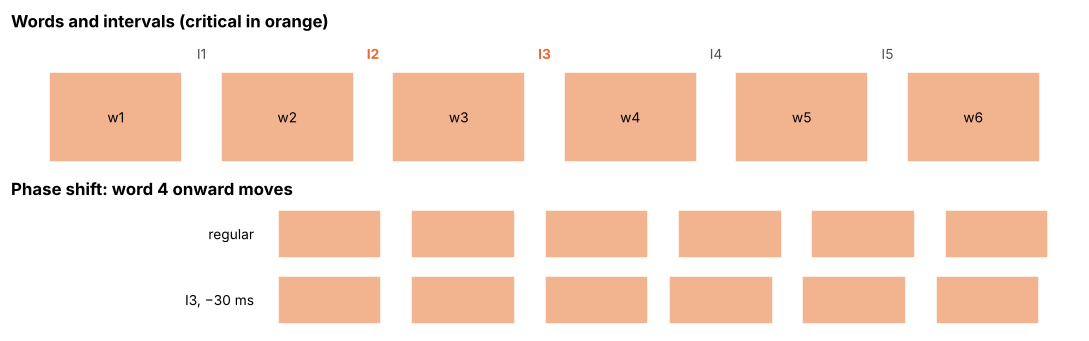

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 3.2))
ax = axes[0]
for w in range(N_WORDS):
    ax.add_patch(Rectangle((w * IOI_MS, 0), EVENT_MS, 1, color="#f2b38f", ec="white"))
    ax.text(w * IOI_MS + EVENT_MS / 2, 0.5, f"w{w + 1}", ha="center", va="center", fontsize=9)
for k, iv in enumerate(INTERVALS, start=1):
    x = (k - 1) * IOI_MS + EVENT_MS + (IOI_MS - EVENT_MS) / 2
    ax.text(x, 1.15, iv, ha="center", fontsize=9, fontweight="bold" if iv in CRITICAL else "normal",
            color="#eb6834" if iv in CRITICAL else "#52514e")
ax.set_xlim(-100, N_WORDS * IOI_MS); ax.set_ylim(0, 1.4); ax.axis("off")
ax.set_title("Words and intervals (critical in orange)", loc="left")
ax = axes[1]
shift = np.zeros(N_WORDS); shift[moved_word("I3") - 1:] = -30
for row, (lab, sh) in enumerate([("regular", np.zeros(N_WORDS)), ("I3, −30 ms", shift)]):
    y = 1.1 - row * 1.1
    for w in range(N_WORDS):
        ax.add_patch(Rectangle((w * IOI_MS + sh[w], y), EVENT_MS, 0.8, color="#f2b38f", ec="white"))
    ax.text(-80, y + 0.4, lab, ha="right", va="center", fontsize=9)
ax.set_xlim(-900, N_WORDS * IOI_MS); ax.set_ylim(-0.1, 2.0); ax.axis("off")
ax.set_title("Phase shift: word 4 onward moves", loc="left")
plt.tight_layout(); plt.show()

### 7.2 Main contrast: critical interval × sentence type
Boundary status is fully crossed with serial position. Each cell = 18 trials (6 size×direction × 3 reps).

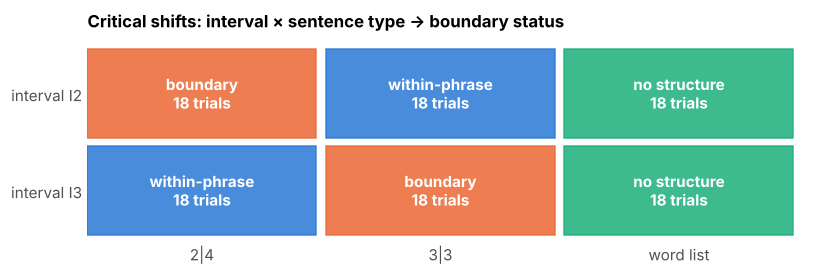

In [9]:
crit = df[df.role.str.startswith("critical")]
t = pd.crosstab(crit.interval, crit.sentence_type)[SENT_TYPES]
status = crit.groupby(["interval", "sentence_type"]).boundary_status.first().unstack()[SENT_TYPES]
SC = {"boundary": "#eb6834", "within-phrase": "#2a78d6", "no structure": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7.5, 2.6))
for i, iv in enumerate(t.index):
    for j, st in enumerate(SENT_TYPES):
        s = status.loc[iv, st]
        ax.add_patch(Rectangle((j, -i - 1), 0.96, 0.92, color=SC[s], alpha=0.85))
        ax.text(j + 0.48, -i - 0.54, f"{s}\n{t.loc[iv, st]} trials", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax.set_xlim(0, 3); ax.set_ylim(-2.05, 0.05)
ax.set_xticks(np.arange(3) + 0.48, SENT_TYPES); ax.set_yticks([-0.54, -1.54], [f"interval {iv}" for iv in t.index])
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Critical shifts: interval × sentence type → boundary status", loc="left")
plt.tight_layout(); plt.show()

### 7.3 Every sentence: its 3 trials (condition and block)
One row per sentence. Columns = I2 trial, I3 trial, third trial (filler or catch). Cell = condition (size ms, ↑ late / ↓ early; filler shows its interval; `catch` = no shift) and **block** in brackets.
**Check:** every row has an I2 and an I3 trial plus one third trial, in 3 different blocks. Within each column, sentences with the same block form the Latin-square groups.

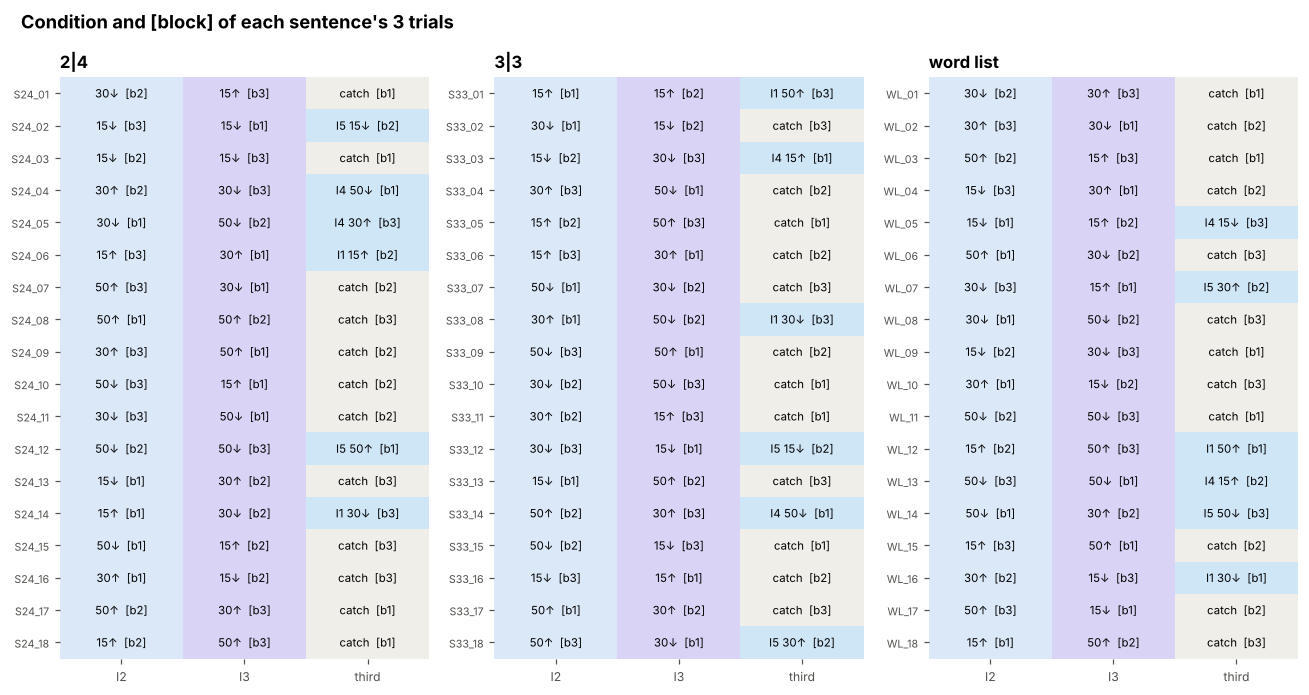

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6.4))
COLS = ["I2", "I3", "third"]
for ax, st in zip(axes, SENT_TYPES):
    d = df[df.sentence_type == st]
    sids = sorted(d.sentence_id.unique())
    img = np.ones((len(sids), 3, 3))
    for _, r in d.iterrows():
        i = sids.index(r.sentence_id)
        j = {"critical_I2": 0, "critical_I3": 1}.get(r.role, 2)
        c = {"critical_I2": "#dbe8f8", "critical_I3": "#d9d3f5", "filler": "#cfe6f7", "catch": "#efeee9"}[r.role]
        img[i, j] = [int(c[k:k + 2], 16) / 255 for k in (1, 3, 5)]
        lab = "catch" if r.role == "catch" else (f"{r.interval} {r.level}" if r.role == "filler" else r.level)
        ax.text(j, i, f"{lab}  [b{r.block}]", ha="center", va="center", fontsize=7.5)
    ax.imshow(img, aspect="auto")
    ax.set_xticks(range(3), COLS, fontsize=8); ax.set_yticks(range(len(sids)), sids, fontsize=7)
    ax.grid(False); ax.set_title(st, loc="left")
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle("Condition and [block] of each sentence's 3 trials", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.4 Critical trials: size × direction
**Check:** every cell = 3 (per sentence type × interval).

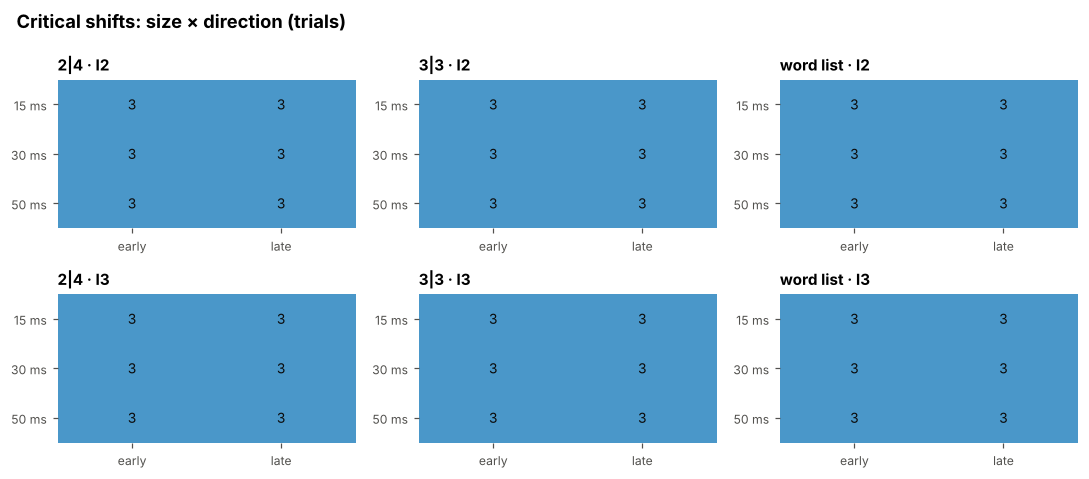

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(10, 4.4))
for c, st in enumerate(SENT_TYPES):
    for r, iv in enumerate(CRITICAL):
        sub = crit[(crit.sentence_type == st) & (crit.interval == iv)]
        t = pd.crosstab(sub.size_ms.astype(int), sub.direction).reindex(index=JITTER_SIZES_MS, columns=DIRECTIONS, fill_value=0)
        t.index = [f"{s} ms" for s in t.index]
        count_heatmap(axes[r, c], t, f"{st} · {iv}", vmax=5)
fig.suptitle("Critical shifts: size × direction (trials)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.5 Filler trials: interval × size × direction
**Check:** each size×direction exactly once per sentence type; each interval has 1 early + 1 late.

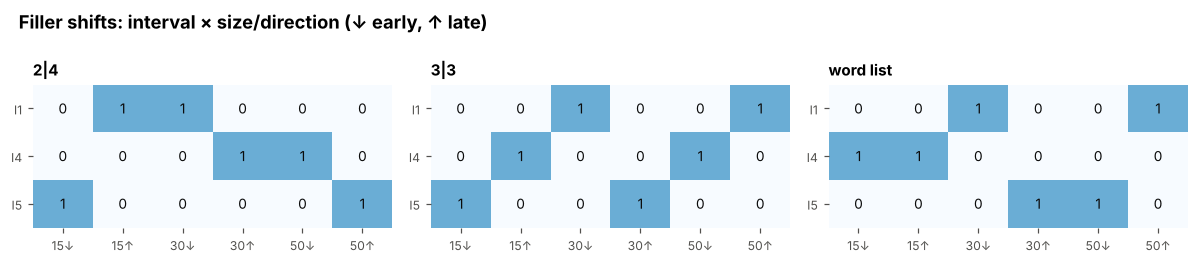

In [12]:
fill = df[df.role == "filler"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.4))
for ax, st in zip(axes, SENT_TYPES):
    d = fill[fill.sentence_type == st]
    t = pd.crosstab(d.interval, d.level).reindex(index=S2_FILLER, columns=LEVELS, fill_value=0)
    count_heatmap(ax, t, st, vmax=2)
fig.suptitle("Filler shifts: interval × size/direction (↓ early, ↑ late)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 7.6 Trial classes and shift positions
Left: trials per role and sentence type (18 / 18 / 6 / 12). Right: where shifts fall – I2 and I3 18 each, fillers 2 each per type; catch = no shift.

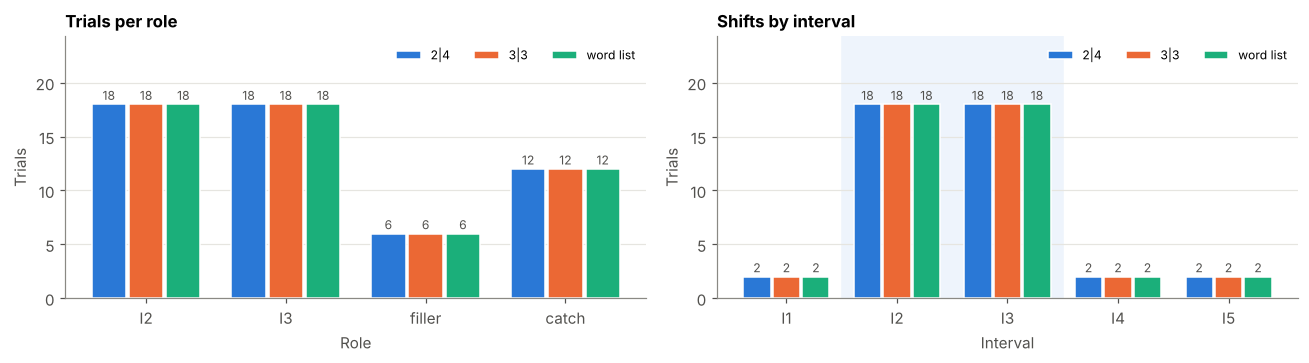

Shifted trials: 126  (critical 108 = 86%, filler 18 = 14%);  catch 36 = 22% of all trials


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
t = pd.crosstab(df.role, df.sentence_type).reindex(ROLES)[SENT_TYPES]; t.index = [ROLE_SHORT[r] for r in t.index]
grouped_bars(axes[0], t, "Trials per role", "Role"); axes[0].legend(ncols=3, fontsize=8, loc="upper right")
s = df[df.jittered]
t = pd.crosstab(s.interval, s.sentence_type).reindex(INTERVALS)[SENT_TYPES]
axes[1].axvspan(0.5, 2.5, color="#eef4fc", zorder=0)
grouped_bars(axes[1], t, "Shifts by interval", "Interval"); axes[1].legend(ncols=3, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
print(f"Shifted trials: {df.jittered.sum()}  (critical {crit.shape[0]} = {crit.shape[0] / df.jittered.sum():.0%}, "
      f"filler {len(fill)} = {len(fill) / df.jittered.sum():.0%});  catch {(~df.jittered).sum()} = {(~df.jittered).mean():.0%} of all trials")

### 7.7 Blocks
**Check:** every block has, per sentence type, 6 I2 + 6 I3 + 2 filler + 4 catch, and each size×direction exactly once at I2 and once at I3.

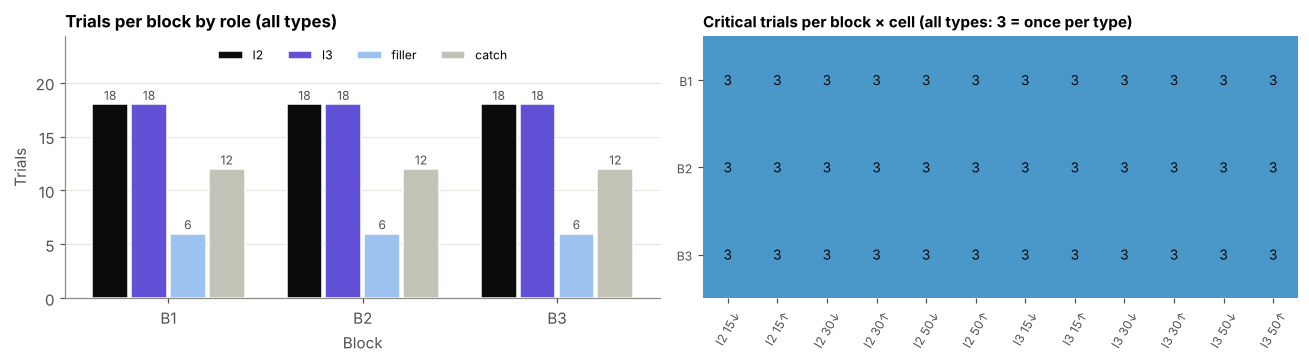

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
t = pd.crosstab(df.block, df.role)[ROLES]; t.index = [f"B{b}" for b in t.index]; t.columns = [ROLE_SHORT[c] for c in t.columns]
grouped_bars(axes[0], t, "Trials per block by role (all types)", "Block", colors={ROLE_SHORT[k]: v for k, v in ROLE_COLORS.items()})
axes[0].legend(ncols=4, fontsize=8, loc="upper center")
cb = crit.assign(cell=crit.interval + " " + crit.level)
t = pd.crosstab(cb.block, cb.cell).reindex(columns=[f"{iv} {l}" for iv in CRITICAL for l in LEVELS]); t.index = [f"B{b}" for b in t.index]
count_heatmap(axes[1], t, "Critical trials per block × cell (all types: 3 = once per type)", vmax=5)
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### 7.8 Exposure and sequence
Left: which hearing (1st–3rd in this task) each role falls on. Because every sentence appears **once per block**, exposure = block number, so every role is **exactly** balanced over exposures (18 / 18 / 6 / 12 at each). Right: the randomized sequence (dashed = breaks).

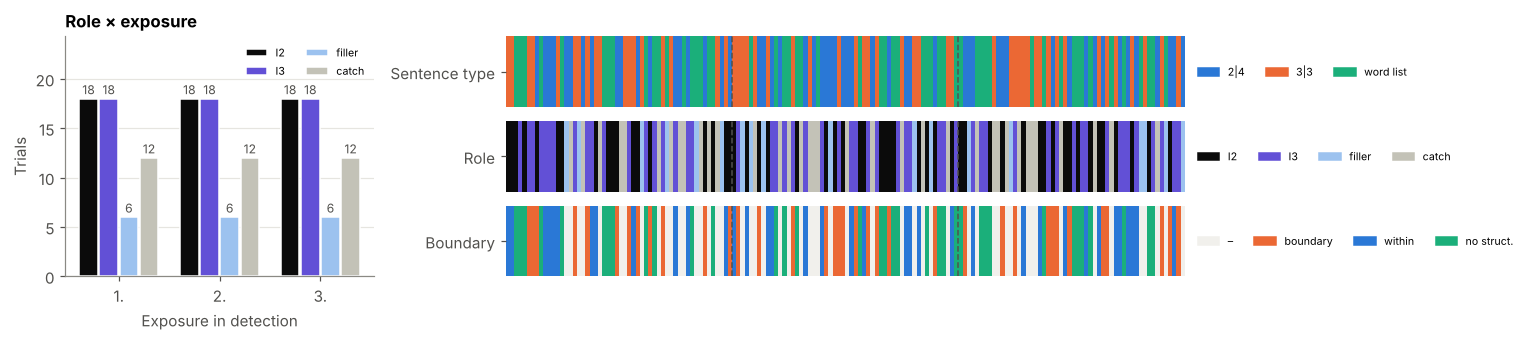

In [15]:
fig = plt.figure(figsize=(14, 3.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 2.2])
ax = fig.add_subplot(gs[0, 0])
t = pd.crosstab(df.exposure, df.role)[ROLES]; t.index = [f"{e}." for e in t.index]; t.columns = [ROLE_SHORT[c] for c in t.columns]
grouped_bars(ax, t, "Role × exposure", "Exposure in detection", colors={ROLE_SHORT[k]: v for k, v in ROLE_COLORS.items()})
ax.legend(ncols=2, fontsize=7)
sub = gs[0, 1].subgridspec(3, 1)
rows = [("Sentence type", df.sentence_type.map({s: i for i, s in enumerate(SENT_TYPES)}), [ST_COLORS[s] for s in SENT_TYPES], SENT_TYPES),
        ("Role", df.role.map({r: i for i, r in enumerate(ROLES)}), [ROLE_COLORS[r] for r in ROLES], [ROLE_SHORT[r] for r in ROLES]),
        ("Boundary", df.boundary_status.map({s: i for i, s in enumerate(["(not critical)", "boundary", "within-phrase", "no structure"])}),
         ["#f1f0ec", "#eb6834", "#2a78d6", "#1baf7a"], ["–", "boundary", "within", "no struct."])]
bounds = np.flatnonzero(np.diff(df.block.values)) + 1
for k, (lab, vals, cols, names) in enumerate(rows):
    a = fig.add_subplot(sub[k])
    a.imshow(vals.values[None, :], aspect="auto", cmap=ListedColormap(cols), vmin=0, vmax=len(names) - 1, interpolation="nearest")
    a.set_yticks([0], [lab]); a.set_xticks([]); a.grid(False)
    for s in a.spines.values(): s.set_visible(False)
    for b in bounds: a.axvline(b - 0.5, color="#52514e", ls="--", lw=1)
    a.legend([Rectangle((0, 0), 1, 1, color=c) for c in cols], names, loc="center left", bbox_to_anchor=(1.005, 0.5), fontsize=7, ncols=len(names))
plt.tight_layout(); plt.show()

## 8. Randomization across participants
40 simulated participants – all pass the checks (same counts), but the item ↔ condition mapping differs.
- **8.1** For each 2|4 sentence: how often (of 40) its I2 trial got each size×direction (expected ≈ 6.7).
- **8.2** For each 2|4 sentence: how often (of 40) its third trial was a filler vs. catch (expected 13.3 filler / 26.7 catch).
- **8.3** Mean exposure of critical trials by boundary status per participant: exactly 2 for everyone, because exposure = block and the Latin square balances roles over blocks.

✓ 40 participants generated, all pass the balance checks


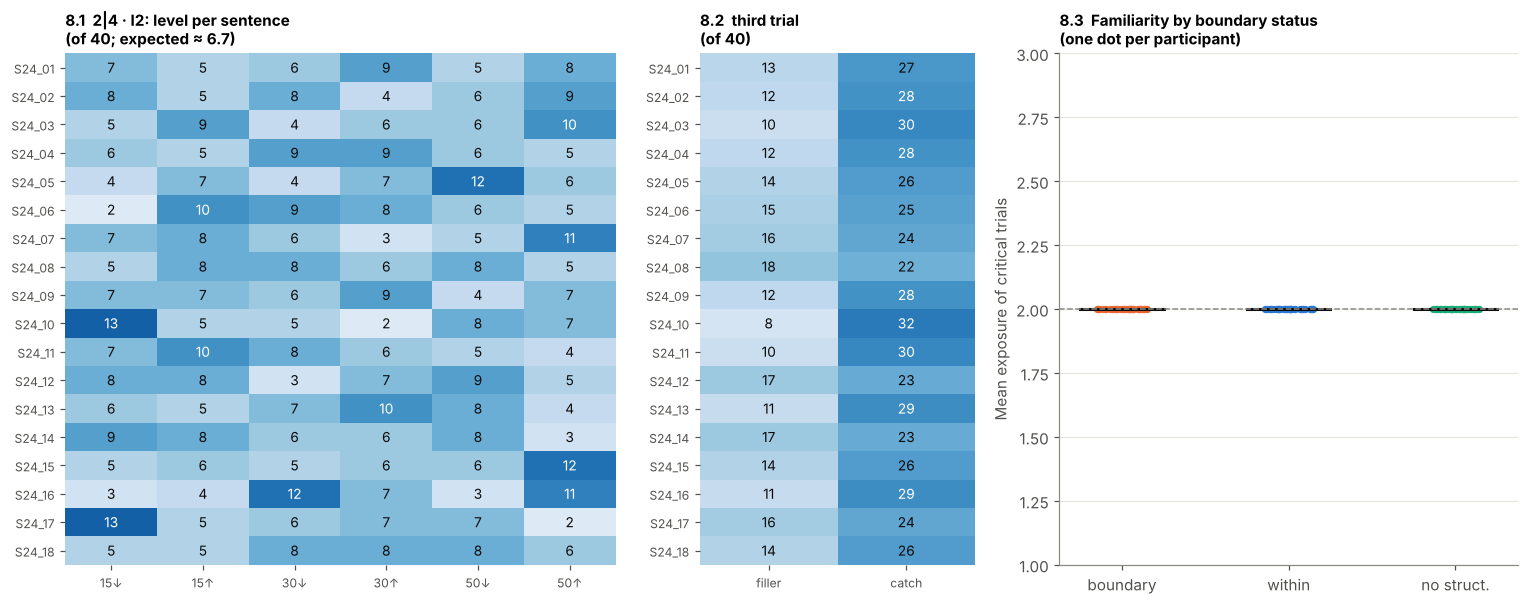

In [16]:
import contextlib, io
sims = [make_design(f"P{i:02d}", "speech" if i % 2 else "acoustic") for i in range(1, 41)]
with contextlib.redirect_stdout(io.StringIO()):
    for d in sims: check_balance(d)
print(f"✓ {len(sims)} participants generated, all pass the balance checks")
sim = pd.concat(sims, ignore_index=True)
sim["level"] = np.where(sim.jittered, sim.size_ms.fillna(0).astype(int).astype(str) + np.where(sim.direction == "late", "↑", "↓"), "–")

fig, axes = plt.subplots(1, 3, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.2, 0.6, 1]})
c2 = sim[(sim.sentence_type == "2|4") & (sim.role == "critical_I2")]
count_heatmap(axes[0], pd.crosstab(c2.sentence_id, c2.level).reindex(columns=LEVELS, fill_value=0),
              "8.1  2|4 · I2: level per sentence\n(of 40; expected ≈ 6.7)", vmax=16)
th = sim[(sim.sentence_type == "2|4") & sim.role.isin(["filler", "catch"])]
count_heatmap(axes[1], pd.crosstab(th.sentence_id, th.role)[["filler", "catch"]],
              "8.2  third trial\n(of 40)", vmax=45)
ex = sim[sim.role.str.startswith("critical")].groupby(["participant", "boundary_status"]).exposure.mean().unstack()
ax = axes[2]
for j, s in enumerate(["boundary", "within-phrase", "no structure"]):
    ax.scatter(np.full(len(ex), j) + np.random.default_rng(j).uniform(-0.15, 0.15, len(ex)), ex[s], s=14,
               color={"boundary": "#eb6834", "within-phrase": "#2a78d6", "no structure": "#1baf7a"}[s])
    ax.plot([j - 0.25, j + 0.25], [ex[s].mean()] * 2, color=INK, lw=2)
ax.axhline(2, color="#8a8984", ls="--", lw=1)
ax.set_xticks(range(3), ["boundary", "within", "no struct."]); ax.set_ylim(1, 3)
ax.set_ylabel("Mean exposure of critical trials"); ax.set_title("8.3  Familiarity by boundary status\n(one dot per participant)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 9. Save the table

In [17]:
Path(OUTPUT_DIR).mkdir(exist_ok=True)
path = Path(OUTPUT_DIR) / f"detection_{PARTICIPANT_ID}_{GROUP}.csv"
df.drop(columns="level").to_csv(path, index=False)
print("Saved", path)

Saved design_tables/detection_P01_speech.csv


## 10. (Optional) Tables for all participants
Uncomment to write one CSV per participant (own seed each → different mapping and order, same counts).

In [18]:
# for i in range(1, 41):
#     pid = f"P{i:02d}"
#     grp = "speech" if i % 2 else "acoustic"
#     d = make_design(pid, grp)
#     check_balance(d)
#     d.to_csv(Path(OUTPUT_DIR) / f"detection_{pid}_{grp}.csv", index=False)